In [1]:
import os

DWSIM_PATH   = r"C:\Users\HomePC\Downloads\DWSIM"                        
SIM_PATH     = r"C:\Users\HomePC\Downloads\LPG_Recovery_v2.dwxmz"     
PROJECT_DIR  = r"C:\Users\HomePC\LPG_Optimization_Project"
DATA_DIR     = os.path.join(PROJECT_DIR, "data")
OUT_CSV      = os.path.join(DATA_DIR, "LPG_v2_Data.csv")

N_SAMPLES    = 3000      # number of random operating points
SWEEP_FEED   = True     
RANDOM_SEED  = 42

# Operating ranges
RANGES = {
    "Chiller_Outlet_Temperature_C":    (15.0, 45.0),    # CL-1 setpoint (AC-1 already cools to 45 C)
    "Compressor_Outlet_Pressure_bar":  (15.0, 35.0),    # C-1 setpoint
    "Feed_Mass_Flow_kgh":              (800.0, 1200.0), # +/- 20% around 1,000 kg/h
    "Feed_Temperature_C":              (25.0, 45.0),    # associated gas arriving at the unit
}
NOMINAL_FEED_FLOW_KGH = 1000.0
NOMINAL_FEED_TEMP_C   = 35.0

# Reflux rule: each column runs at RR_FACTOR x its minimum reflux
RR_FACTOR = 1.3
RR_PROBE  = 20.0     # high reflux used in the first pass to find the minimum

os.makedirs(DATA_DIR, exist_ok=True)

In [2]:
import sys
from pythonnet import load
load("coreclr")
import clr

os.chdir(DWSIM_PATH)
if DWSIM_PATH not in sys.path:
    sys.path.append(DWSIM_PATH)

for ref in ["CapeOpen", "DWSIM.Automation", "DWSIM.Interfaces", "DWSIM.GlobalSettings",
            "DWSIM.SharedClasses", "DWSIM.Thermodynamics"]:
    clr.AddReference(ref)

from DWSIM.Automation import Automation3

interf = Automation3()
sim = interf.LoadFlowsheet(SIM_PATH)

def obj(tag):
    o = sim.GetFlowsheetSimulationObject(tag)
    if o is None:
        raise KeyError(f"Object '{tag}' not found in the flowsheet. Check the name in DWSIM.")
    return o.GetAsObject()

# Units and setpoints
feed       = obj("Raw_Associated_Gas")
compressor = obj("C-1")
chiller    = obj("CL-1")
scol1      = obj("SCOL-1")
scol2      = obj("SCOL-2")

# Energy streams (kW)
ENERGY = {
    "Compressor_Power_kW":       obj("E1"),
    "Air_Cooler_Duty_kW":        obj("E_AC1"),
    "Chiller_Duty_kW":           obj("E2"),
    "Deethanizer_Condenser_kW":  obj("Q_Condenser"),
    "Deethanizer_Reboiler_kW":   obj("Q_Reboiler"),
    "Debutanizer_Condenser_kW":  obj("E5"),
    "Debutanizer_Reboiler_kW":   obj("E6"),
}

# Material streams i read
s_comp_out = obj("2")
s_sales    = obj("Sales_Gas_C1_C2")
s_lpg      = obj("Pure_LPG")
s_light    = obj("Light_Gas_Top")
print("Flowsheet loaded and all objects found.")

Flowsheet loaded and all objects found.


In [3]:
import math
import time
import numpy as np
import pandas as pd

def mole_frac(stream, name):
    """Overall mole fraction of one compound in a stream (NaN if unavailable)."""
    try:
        v = stream.Phases[0].Compounds[name].MoleFraction
        return float(v) if v is not None else math.nan
    except Exception:
        return math.nan

def set_point(t_chiller_c, p_comp_bar, feed_kgh, feed_t_c):
    chiller.OutletTemperature = float(t_chiller_c + 273.15)
    compressor.POut = float(p_comp_bar * 1e5)
    feed.SetMassFlow(float(feed_kgh / 3600.0))
    feed.SetTemperature(float(feed_t_c + 273.15))

def _solve_once():
    """One flowsheet solve. Returns (status_or_None, solve_ms)."""
    t0 = time.perf_counter()
    try:
        errors = interf.CalculateFlowsheet2(sim)
    except Exception as e:  # a .NET exception should not stop the sweep
        return f"Failed (Exception): {e}", (time.perf_counter() - t0) * 1000.0
    ms = (time.perf_counter() - t0) * 1000.0
    if errors is not None and errors.Count > 0:
        return f"Failed (Global): {errors[0].Message}", ms
    for name, col in (("SCOL-1", scol1), ("SCOL-2", scol2)):
        msg = str(col.ErrorMessage or "").strip()
        if msg:
            return f"Failed ({name}): {msg}", ms
    return None, ms

def solve_and_read():
    """Two-pass solve: (1) high reflux to get each column's minimum reflux,
    (2) reflux = RR_FACTOR x minimum, then read all results."""
    out = {}
    # Pass 1: probe
    scol1.m_refluxratio = RR_PROBE
    scol2.m_refluxratio = RR_PROBE
    status, ms1 = _solve_once()
    out["Probe_Solve_Time_ms"] = ms1
    if status:
        out["Solve_Time_ms"] = ms1
        return out, status

    rmin1, rmin2 = float(scol1.m_Rmin), float(scol2.m_Rmin)
    out["Deethanizer_Rmin"], out["Debutanizer_Rmin"] = rmin1, rmin2
    if not (np.isfinite(rmin1) and rmin1 > 0 and np.isfinite(rmin2) and rmin2 > 0):
        out["Solve_Time_ms"] = ms1
        return out, f"Invalid (Rmin: {rmin1:.3f}, {rmin2:.3f})"

    # Pass 2: design reflux
    scol1.m_refluxratio = RR_FACTOR * rmin1
    scol2.m_refluxratio = RR_FACTOR * rmin2
    out["Deethanizer_Reflux"], out["Debutanizer_Reflux"] = RR_FACTOR * rmin1, RR_FACTOR * rmin2
    status, ms2 = _solve_once()
    out["Solve_Time_ms"] = ms2          # time of one rigorous evaluation, used for the speed benchmark
    if status:
        return out, status

    for key, es in ENERGY.items():
        out[key] = abs(float(es.EnergyFlow))
    out["LPG_kgh"] = float(s_lpg.GetMassFlow()) * 3600.0
    out["Compressor_Discharge_T_C"]    = float(s_comp_out.GetTemperature()) - 273.15
    out["Deethanizer_Condenser_T_C"]   = float(s_sales.GetTemperature()) - 273.15   # partial condenser: distillate leaves at condenser T
    out["Debutanizer_Condenser_T_C"]   = float(s_lpg.GetTemperature()) - 273.15
    out["Deethanizer_Stages"]  = float(scol1.m_N)
    out["Debutanizer_Stages"]  = float(scol2.m_N)
    out["LPG_Ethane_molfrac"]    = mole_frac(s_lpg, "Ethane")
    out["LPG_Propane_molfrac"]   = mole_frac(s_lpg, "Propane")
    out["LPG_Butanes_molfrac"]   = mole_frac(s_lpg, "N-butane") + mole_frac(s_lpg, "Isobutane")
    out["LPG_Pentanes_molfrac"]  = mole_frac(s_lpg, "N-pentane") + mole_frac(s_lpg, "Isopentane")
    out["Light_Gas_Propane_molfrac"] = mole_frac(s_light, "Propane")  # LPG lost to the light gas

    if not np.isfinite(out["LPG_kgh"]) or out["LPG_kgh"] < 0.1:
        return out, "Invalid (LPG < 0.1 kg/h)"
    if any(not np.isfinite(out[k]) for k in ENERGY):
        return out, "Invalid (NaN duty)"
    return out, "Success"

## Checking the base case first
LPG should be about **57.5 kg/h**, sales gas about **−43 °C**, air cooler about **34.4 kW** and chiller about **22.5 kW**, the same as in DWSIM. 

In [4]:
set_point(25.0, 25.0, NOMINAL_FEED_FLOW_KGH, NOMINAL_FEED_TEMP_C)
res, status = solve_and_read()
print("Status:", status)
for k in ["LPG_kgh", "Deethanizer_Condenser_T_C", "Debutanizer_Condenser_T_C",
          "Compressor_Power_kW", "Air_Cooler_Duty_kW", "Chiller_Duty_kW",
          "Deethanizer_Condenser_kW", "Deethanizer_Reboiler_kW",
          "Debutanizer_Condenser_kW", "Debutanizer_Reboiler_kW",
          "Deethanizer_Rmin", "Deethanizer_Reflux", "Debutanizer_Rmin", "Debutanizer_Reflux",
          "Probe_Solve_Time_ms", "Solve_Time_ms"]:
    print(f"  {k:28s} {res.get(k, float('nan')):10.3f}")

Status: Success
  LPG_kgh                          57.495
  Deethanizer_Condenser_T_C       -43.227
  Debutanizer_Condenser_T_C        49.002
  Compressor_Power_kW              33.185
  Air_Cooler_Duty_kW               34.424
  Chiller_Duty_kW                  22.480
  Deethanizer_Condenser_kW          1.944
  Deethanizer_Reboiler_kW           8.269
  Debutanizer_Condenser_kW         13.006
  Debutanizer_Reboiler_kW          13.009
  Deethanizer_Rmin                  0.829
  Deethanizer_Reflux                1.077
  Debutanizer_Rmin                  1.122
  Debutanizer_Reflux                1.459
  Probe_Solve_Time_ms            2287.292
  Solve_Time_ms                   309.781


In [5]:
def latin_hypercube(n, ranges, rng):
    cols = {}
    for name, (lo, hi) in ranges.items():
        strata = (np.arange(n) + rng.random(n)) / n   # one point in each of n equal slices
        rng.shuffle(strata)
        cols[name] = lo + strata * (hi - lo)
    return pd.DataFrame(cols)

rng = np.random.default_rng(RANDOM_SEED)
plan = latin_hypercube(N_SAMPLES, RANGES, rng)
if not SWEEP_FEED:
    plan["Feed_Mass_Flow_kgh"] = NOMINAL_FEED_FLOW_KGH
    plan["Feed_Temperature_C"] = NOMINAL_FEED_TEMP_C
plan.describe().T[["min", "mean", "max"]]

,min,mean,max
Chiller_Outlet_Temperature_C,15.007740,29.999995,44.990981
Compressor_Outlet_Pressure_bar,15.004386,24.999993,34.995946
Feed_Mass_Flow_kgh,800.010282,999.999407,1199.996000
Feed_Temperature_C,25.005779,35.000035,44.998922


In [6]:
records = []
start = time.time()
for i, row in plan.iterrows():
    set_point(row["Chiller_Outlet_Temperature_C"], row["Compressor_Outlet_Pressure_bar"],
              row["Feed_Mass_Flow_kgh"], row["Feed_Temperature_C"])
    res, status = solve_and_read()
    rec = row.to_dict()
    rec.update(res)
    rec["Solve_Status"] = status
    records.append(rec)

    n = i + 1
    if n % 250 == 0 or n == 1 or n == len(plan):
        ok = sum(r["Solve_Status"] == "Success" for r in records)
        print(f"[{n}/{len(plan)}] {time.time() - start:6.1f}s | converged {ok}/{n} | last: {status}")
        pd.DataFrame(records).to_csv(OUT_CSV, index=False)   # checkpoint

df = pd.DataFrame(records)
df.to_csv(OUT_CSV, index=False)
print(f"\nSaved {len(df)} rows to {OUT_CSV}")

[1/3000]    0.6s | converged 1/1 | last: Success
[250/3000]   51.6s | converged 230/250 | last: Success
[500/3000]  101.1s | converged 460/500 | last: Success
[750/3000]  149.9s | converged 691/750 | last: Success
[1000/3000]  200.1s | converged 925/1000 | last: Success
[1250/3000]  252.0s | converged 1154/1250 | last: Success
[1500/3000]  305.4s | converged 1384/1500 | last: Success
[1750/3000]  355.5s | converged 1618/1750 | last: Success
[2000/3000]  404.3s | converged 1842/2000 | last: Failed (SCOL-1): Invalid value for Distillate Rate: NaN (Parameter 'D')
[2250/3000]  454.8s | converged 2079/2250 | last: Success
[2500/3000]  503.8s | converged 2308/2500 | last: Success
[2750/3000]  552.4s | converged 2539/2750 | last: Success
[3000/3000]  599.8s | converged 2764/3000 | last: Success

Saved 3000 rows to C:\Users\HomePC\LPG_Optimization_Project\data\LPG_v2_Data.csv


In [7]:
df = pd.read_csv(OUT_CSV)
ok = df[df["Solve_Status"] == "Success"].copy()
print(f"Converged: {len(ok)} of {len(df)} ({len(ok)/len(df):.1%})")
print("\nFailure types:")
print(df.loc[df["Solve_Status"] != "Success", "Solve_Status"].str[:80].value_counts().to_string())

print("\nOne rigorous solve (ms): mean %.1f, median %.1f, max %.1f"
      % (df["Solve_Time_ms"].mean(), df["Solve_Time_ms"].median(), df["Solve_Time_ms"].max()))

print("\nRanges over converged points:")
cols = ["LPG_kgh", "Deethanizer_Rmin", "Debutanizer_Rmin", "Deethanizer_Stages", "Debutanizer_Stages", "Deethanizer_Condenser_T_C", "Debutanizer_Condenser_T_C",
        "Compressor_Discharge_T_C", "LPG_Ethane_molfrac", "LPG_Pentanes_molfrac"]
print(ok[cols].describe().T[["min", "50%", "max"]].round(3).to_string())

# Physical sanity flags
print("\nPoints with deethanizer condenser colder than -50 C:", int((ok["Deethanizer_Condenser_T_C"] < -50).sum()))
print("Points with debutanizer condenser below 45 C (air cooling not enough):", int((ok["Debutanizer_Condenser_T_C"] < 45).sum()))
print("Points with LPG ethane above 2 mol%:", int((ok["LPG_Ethane_molfrac"] > 0.02).sum()))
print("Points with LPG pentanes above 2 mol%:", int((ok["LPG_Pentanes_molfrac"] > 0.02).sum()))

Converged: 2764 of 3000 (92.1%)

Failure types:
Solve_Status
Failed (SCOL-1): Invalid value for Distillate Rate: NaN (Parameter 'D')    235
Invalid (LPG < 0.1 kg/h)                                                     1

One rigorous solve (ms): mean 102.2, median 96.7, max 416.0

Ranges over converged points:
                              min      50%      max
LPG_kgh                     0.144   40.587  149.623
Deethanizer_Rmin            0.588    0.877    1.073
Debutanizer_Rmin            0.793    1.207    1.865
Deethanizer_Stages         22.167   23.193   24.656
Debutanizer_Stages         25.185   25.771   26.265
Deethanizer_Condenser_T_C -46.270  -43.678  -40.357
Debutanizer_Condenser_T_C  46.019   49.227   51.338
Compressor_Discharge_T_C   55.537  102.560  135.462
LPG_Ethane_molfrac          0.001    0.002    0.003
LPG_Pentanes_molfrac        0.012    0.012    0.012

Points with deethanizer condenser colder than -50 C: 0
Points with debutanizer condenser below 45 C (air cooling not

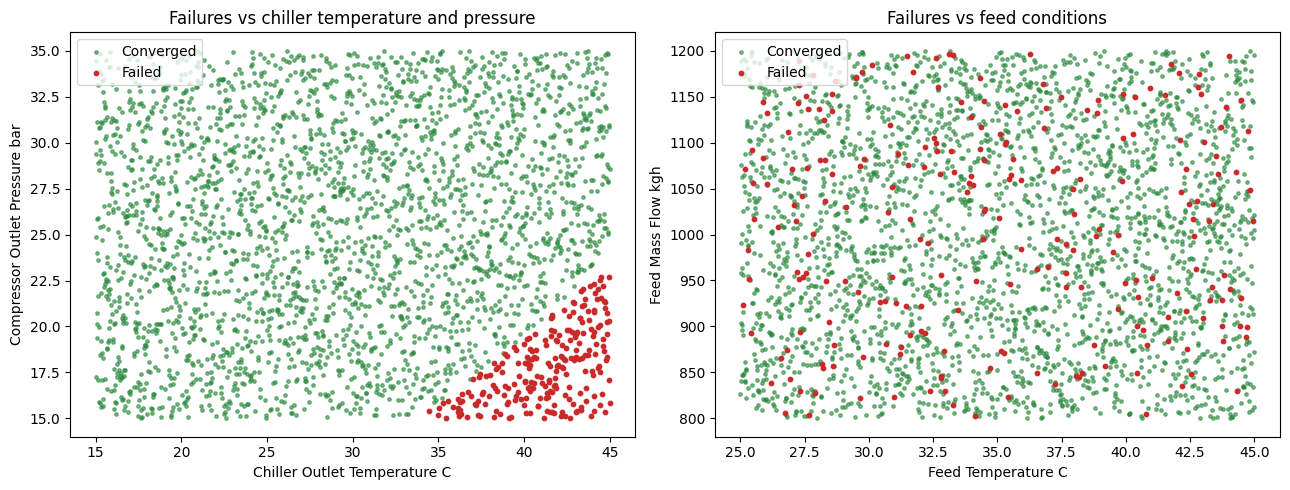

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
good = df["Solve_Status"] == "Success"
for ax, (x, y) in zip(axes, [("Chiller_Outlet_Temperature_C", "Compressor_Outlet_Pressure_bar"),
                             ("Feed_Temperature_C", "Feed_Mass_Flow_kgh")]):
    ax.scatter(df.loc[good, x], df.loc[good, y], s=6, c="#2b8a3e", label="Converged", alpha=0.6)
    ax.scatter(df.loc[~good, x], df.loc[~good, y], s=10, c="#c92a2a", label="Failed")
    ax.set_xlabel(x.replace("_", " ")); ax.set_ylabel(y.replace("_", " ")); ax.legend()
axes[0].set_title("Failures vs chiller temperature and pressure")
axes[1].set_title("Failures vs feed conditions")
plt.tight_layout(); plt.show()